<a href="https://colab.research.google.com/github/lkjidm/LLMgroup2/blob/br-1/P01_SMHI_data_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [1]:
!pip install -q requests pandas numpy matplotlib seaborn plotly scipy statsmodels
# Later we will add more (google-genai, transformers, etc.) when we build the agent

In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import json
from IPython.display import display, Markdown

In [3]:
from google.colab import userdata
# Optional – we only need these when we build the LLM agent
try:
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
    print("Gemini key loaded")
except:
    GEMINI_API_KEY = None
    print("No Gemini key yet")

try:
    HF_TOKEN = userdata.get("HF_TOKEN")
    print("HF token loaded")
except:
    HF_TOKEN = None
    print("No HF token yet")

Gemini key loaded
HF token loaded


In [4]:
# Entry point of the Meteorological Observations API
url = "https://opendata-download-metobs.smhi.se/api/version/latest.json"
r = requests.get(url)
print("Status:", r.status_code)
data = r.json()

# Show available parameters (first 15)
print("\nAvailable parameters (sample):")
for resource in data.get("resource", [])[:15]:
    print(f"  ID {resource['key']}: {resource['title']} ({resource.get('summary', '')})")

Status: 200

Available parameters (sample):
  ID 21: Byvind (max, 1 gång/tim)
  ID 39: Daggpunktstemperatur (momentanvärde, 1 gång/tim)
  ID 11: Global Irradians (svenska stationer) (medelvärde 1 timma, varje timme)
  ID 45: Lufttemperatur (momentanvärde varje minut)
  ID 19: Lufttemperatur (min, 1 gång per dygn)
  ID 1: Lufttemperatur (momentanvärde, 1 gång/tim)
  ID 2: Lufttemperatur (medelvärde 1 dygn, 1 gång/dygn, kl 00)
  ID 20: Lufttemperatur (max, 1 gång per dygn)
  ID 22: Lufttemperatur (medel, 1 gång per månad)
  ID 26: Lufttemperatur (min, 2 gånger per dygn, kl 06 och 18)
  ID 27: Lufttemperatur (max, 2 gånger per dygn, kl 06 och 18)
  ID 44: Lufttryck reducerat havsytans nivå (momentanvärde varje minut)
  ID 9: Lufttryck reducerat havsytans nivå (vid havsytans nivå, momentanvärde, 1 gång/tim)
  ID 24: Långvågs-Irradians (medelvärde 1 timma, varje timme)
  ID 40: Markens tillstånd (momentanvärde, 1 gång/dygn, kl 06)


In [5]:
# Look at stations for parameter 1 (hourly temperature)
param_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/1.json"
r = requests.get(param_url)
stations = r.json().get("station", [])

# Filter for Uppsala-related stations
uppsala_stations = [s for s in stations if "uppsala" in s.get("name", "").lower()]
print(f"Found {len(uppsala_stations)} Uppsala-related stations:\n")
for s in uppsala_stations:
    print(f"ID: {s['id']}  |  Name: {s['name']}  |  Active: {s.get('active')}  |  Lat/Lon: {s.get('latitude')}, {s.get('longitude')}")

Found 3 Uppsala-related stations:

ID: 97520  |  Name: Uppsala  |  Active: False  |  Lat/Lon: 59.8585, 17.6219
ID: 97510  |  Name: Uppsala Aut  |  Active: True  |  Lat/Lon: 59.8471, 17.632
ID: 97530  |  Name: Uppsala Flygplats  |  Active: True  |  Lat/Lon: 59.9, 17.593


In [6]:
# Example: corrected-archive for daily max temperature (parameter 20) at Uppsala Aut (97510)
# First check available periods
period_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/20/station/97510.json"
r = requests.get(period_url)
print("Available periods:")
for p in r.json().get("period", []):
    print(f"  {p['key']}: {p['title']}")

Available periods:
  latest-day: Data från senaste dygnet
  latest-months: Data från senaste fyra månaderna
  corrected-archive: Kvalitetskontrollerade historiska data (utom de senaste 3 mån)


In [7]:
# Download CSV for a period (example – adjust the period key after you see the list above)
data_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/20/station/97510/period/latest-months/data.csv"
df = pd.read_csv(data_url, sep=";", skiprows=10)  # SMHI CSVs often have header rows
print(df.head(20))
print("\nColumns:", df.columns.tolist())
print("\nShape:", df.shape)

   Från Datum Tid (UTC) Till Datum Tid (UTC) Representativt dygn  \
0   2026-06-02 18:00:01  2026-06-03 18:00:00          2026-06-03   
1   2026-06-03 18:00:01  2026-06-04 18:00:00          2026-06-04   
2   2026-06-04 18:00:01  2026-06-05 18:00:00          2026-06-05   
3   2026-06-05 18:00:01  2026-06-06 18:00:00          2026-06-06   
4   2026-06-06 18:00:01  2026-06-07 18:00:00          2026-06-07   
5   2026-06-07 18:00:01  2026-06-08 18:00:00          2026-06-08   
6   2026-06-08 18:00:01  2026-06-09 18:00:00          2026-06-09   
7   2026-06-09 18:00:01  2026-06-10 18:00:00          2026-06-10   
8   2026-06-10 18:00:01  2026-06-11 18:00:00          2026-06-11   
9   2026-06-11 18:00:01  2026-06-12 18:00:00          2026-06-12   
10  2026-06-12 18:00:01  2026-06-13 18:00:00          2026-06-13   
11  2026-06-13 18:00:01  2026-06-14 18:00:00          2026-06-14   
12  2026-06-14 18:00:01  2026-06-15 18:00:00          2026-06-15   
13  2026-06-15 18:00:01  2026-06-16 18:00:00    

In [8]:
# Clean the data we just downloaded
df_clean = df.copy()

# Keep only rows that have a real date and a temperature value
df_clean = df_clean.dropna(subset=["Representativt dygn", "Lufttemperatur"])

# Convert date column
df_clean["date"] = pd.to_datetime(df_clean["Representativt dygn"])

# Keep only the useful columns and rename
df_clean = df_clean[["date", "Lufttemperatur", "Kvalitet"]].rename(
    columns={"Lufttemperatur": "tmax", "Kvalitet": "quality"}
)

# Sort by date
df_clean = df_clean.sort_values("date").reset_index(drop=True)

print("Cleaned data shape:", df_clean.shape)
print("\nFirst 10 rows:")
print(df_clean.head(10))
print("\nLast 5 rows:")
print(df_clean.tail())
print("\nBasic statistics:")
print(df_clean["tmax"].describe())

Cleaned data shape: (131, 3)

First 10 rows:
        date  tmax quality
0 2026-06-03  25.2       Y
1 2026-06-04  20.6       Y
2 2026-06-05  18.9       Y
3 2026-06-06  20.6       Y
4 2026-06-07  22.8       Y
5 2026-06-08  24.8       Y
6 2026-06-09  23.4       Y
7 2026-06-10  20.3       Y
8 2026-06-11  19.0       Y
9 2026-06-12  21.6       Y

Last 5 rows:
          date  tmax quality
126 2026-10-07  14.8       Y
127 2026-10-08  13.3       Y
128 2026-10-09  12.7       Y
129 2026-10-10   8.0       Y
130 2026-10-11   7.3       Y

Basic statistics:
count    131.000000
mean      21.445038
std        4.519347
min        7.300000
25%       18.100000
50%       21.400000
75%       24.550000
max       32.000000
Name: tmax, dtype: float64


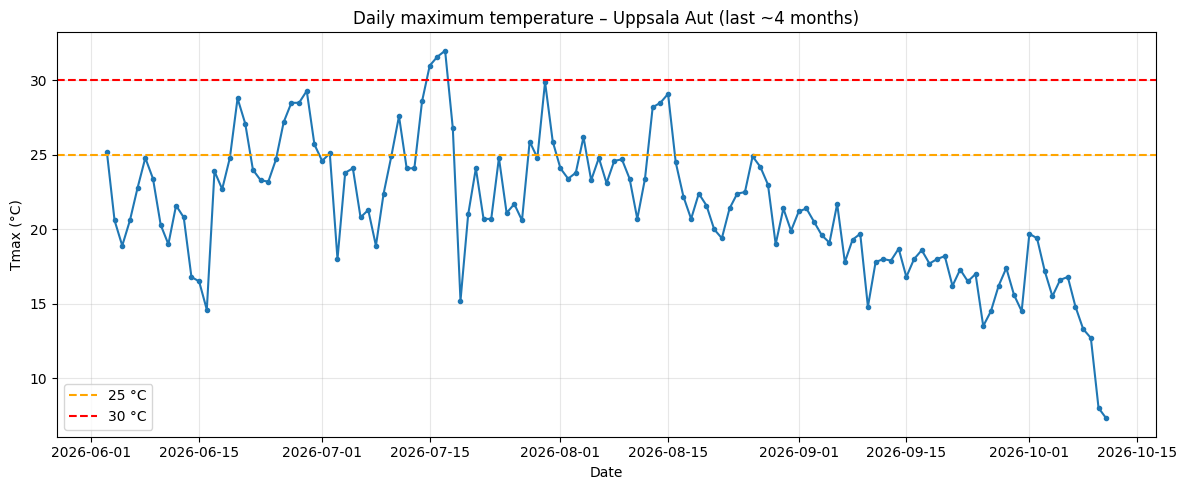

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(df_clean["date"], df_clean["tmax"], marker="o", markersize=3)
plt.axhline(25, color="orange", linestyle="--", label="25 °C")
plt.axhline(30, color="red", linestyle="--", label="30 °C")
plt.title("Daily maximum temperature – Uppsala Aut (last ~4 months)")
plt.ylabel("Tmax (°C)")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Download quality-controlled historical daily max temperature (parameter 20, station 97510)
archive_url = "https://opendata-download-metobs.smhi.se/api/version/latest/parameter/20/station/97510/period/corrected-archive/data.csv"

# SMHI puts metadata at the top – we skip the first ~10 rows and let pandas handle the rest
df_hist = pd.read_csv(archive_url, sep=";", skiprows=10)

print("Raw archive shape:", df_hist.shape)
print("\nFirst 5 rows of raw data:")
print(df_hist.head())
print("\nColumns:", df_hist.columns.tolist())

Raw archive shape: (15004, 7)

First 5 rows of raw data:
  Från Datum Tid (UTC) Till Datum Tid (UTC) Representativt dygn  \
0  1985-05-31 18:00:01  1985-06-01 18:00:00          1985-06-01   
1  1985-06-01 18:00:01  1985-06-02 18:00:00          1985-06-02   
2  1985-06-02 18:00:01  1985-06-03 18:00:00          1985-06-03   
3  1985-06-03 18:00:01  1985-06-04 18:00:00          1985-06-04   
4  1985-06-04 18:00:01  1985-06-05 18:00:00          1985-06-05   

   Lufttemperatur Kvalitet  Unnamed: 5  \
0            22.8        G         NaN   
1            21.3        G         NaN   
2            17.8        G         NaN   
3            21.7        G         NaN   
4            15.7        G         NaN   

                                        Tidsutsnitt:  
0  Kvalitetskontrollerade historiska data (utom d...  
1   Tidsperiod (fr.o.m.) = 1985-06-01 00:00:00 (UTC)  
2    Tidsperiod (t.o.m.) = 2026-07-01 06:00:00 (UTC)  
3                           Samplingstid = 24 timmar  
4           

In [12]:
# Clean exactly like before
df_hist_clean = df_hist.copy()
df_hist_clean = df_hist_clean.dropna(subset=["Representativt dygn", "Lufttemperatur"])
df_hist_clean["date"] = pd.to_datetime(df_hist_clean["Representativt dygn"])
df_hist_clean = df_hist_clean[["date", "Lufttemperatur", "Kvalitet"]].rename(
    columns={"Lufttemperatur": "tmax", "Kvalitet": "quality"}
)
df_hist_clean = df_hist_clean.sort_values("date").reset_index(drop=True)

print("Cleaned historical data shape:", df_hist_clean.shape)
print("\nDate range:")
print("  First day:", df_hist_clean["date"].min().date())
print("  Last day :", df_hist_clean["date"].max().date())
print("\nBasic statistics:")
print(df_hist_clean["tmax"].describe())
print("\nFirst 5 rows:")
print(df_hist_clean.head())
print("\nLast 5 rows:")
print(df_hist_clean.tail())

Cleaned historical data shape: (15004, 3)

Date range:
  First day: 1985-06-01
  Last day : 2026-06-30

Basic statistics:
count    15004.000000
mean        11.123314
std          9.309148
min        -22.500000
25%          3.600000
50%         10.900000
75%         19.000000
max         34.400000
Name: tmax, dtype: float64

First 5 rows:
        date  tmax quality
0 1985-06-01  22.8       G
1 1985-06-02  21.3       G
2 1985-06-03  17.8       G
3 1985-06-04  21.7       G
4 1985-06-05  15.7       G

Last 5 rows:
            date  tmax quality
14999 2026-06-26  27.2       Y
15000 2026-06-27  28.5       Y
15001 2026-06-28  28.5       Y
15002 2026-06-29  29.3       Y
15003 2026-06-30  25.7       Y


In [13]:
# Work on a copy of the historical data
df = df_hist_clean.copy()

# Define heat days (you can change the threshold later)
THRESHOLD = 30.0          # °C – classic Swedish heat threshold
df["is_heat_day"] = df["tmax"] >= THRESHOLD

# Identify consecutive heatwave periods
df["heatwave_id"] = (df["is_heat_day"] != df["is_heat_day"].shift()).cumsum()
df.loc[~df["is_heat_day"], "heatwave_id"] = 0

# Keep only real heatwaves (at least 1 day for now; we can require ≥2 or ≥3 later)
heatwaves = (
    df[df["is_heat_day"]]
    .groupby("heatwave_id")
    .agg(
        start=("date", "min"),
        end=("date", "max"),
        duration=("date", "count"),
        max_tmax=("tmax", "max"),
        mean_tmax=("tmax", "mean")
    )
    .reset_index(drop=True)
)

print(f"Number of heat days (Tmax ≥ {THRESHOLD}°C): {df['is_heat_day'].sum()}")
print(f"Number of heatwave periods: {len(heatwaves)}")
print("\nHeatwaves found:")
print(heatwaves.sort_values("start"))

Number of heat days (Tmax ≥ 30.0°C): 105
Number of heatwave periods: 56

Heatwaves found:
        start        end  duration  max_tmax  mean_tmax
0  1986-06-26 1986-06-26         1      31.0  31.000000
1  1989-07-05 1989-07-05         1      30.7  30.700000
2  1989-07-07 1989-07-08         2      30.7  30.700000
3  1991-07-07 1991-07-07         1      30.0  30.000000
4  1994-07-12 1994-07-15         4      33.3  31.875000
5  1994-07-26 1994-07-29         4      33.2  32.225000
6  1994-08-05 1994-08-05         1      30.5  30.500000
7  1995-08-18 1995-08-18         1      30.9  30.900000
8  1997-07-01 1997-07-01         1      30.4  30.400000
9  1999-07-11 1999-07-12         2      30.9  30.850000
10 1999-07-14 1999-07-14         1      30.2  30.200000
11 1999-08-01 1999-08-04         4      31.0  30.450000
12 2001-07-04 2001-07-09         6      31.5  30.750000
13 2003-07-16 2003-07-17         2      30.3  30.150000
14 2004-08-08 2004-08-08         1      30.9  30.900000
15 2005-07-08 

In [14]:
print("Heatwave duration statistics:")
print(heatwaves["duration"].describe())

print("\nHottest heatwaves (by max temperature):")
print(heatwaves.sort_values("max_tmax", ascending=False).head(10))

Heatwave duration statistics:
count    56.000000
mean      1.875000
std       1.465513
min       1.000000
25%       1.000000
50%       1.000000
75%       2.000000
max       8.000000
Name: duration, dtype: float64

Hottest heatwaves (by max temperature):
        start        end  duration  max_tmax  mean_tmax
38 2018-07-13 2018-07-20         8      34.4  32.475000
39 2018-07-24 2018-07-27         4      34.3  33.025000
52 2022-07-21 2022-07-21         1      33.7  33.700000
4  1994-07-12 1994-07-15         4      33.3  31.875000
32 2014-08-04 2014-08-04         1      33.3  33.300000
5  1994-07-26 1994-07-29         4      33.2  32.225000
42 2019-07-25 2019-07-28         4      32.8  31.250000
25 2010-07-11 2010-07-13         3      32.6  31.866667
16 2005-07-11 2005-07-12         2      32.5  31.300000
47 2021-07-14 2021-07-15         2      32.3  31.950000


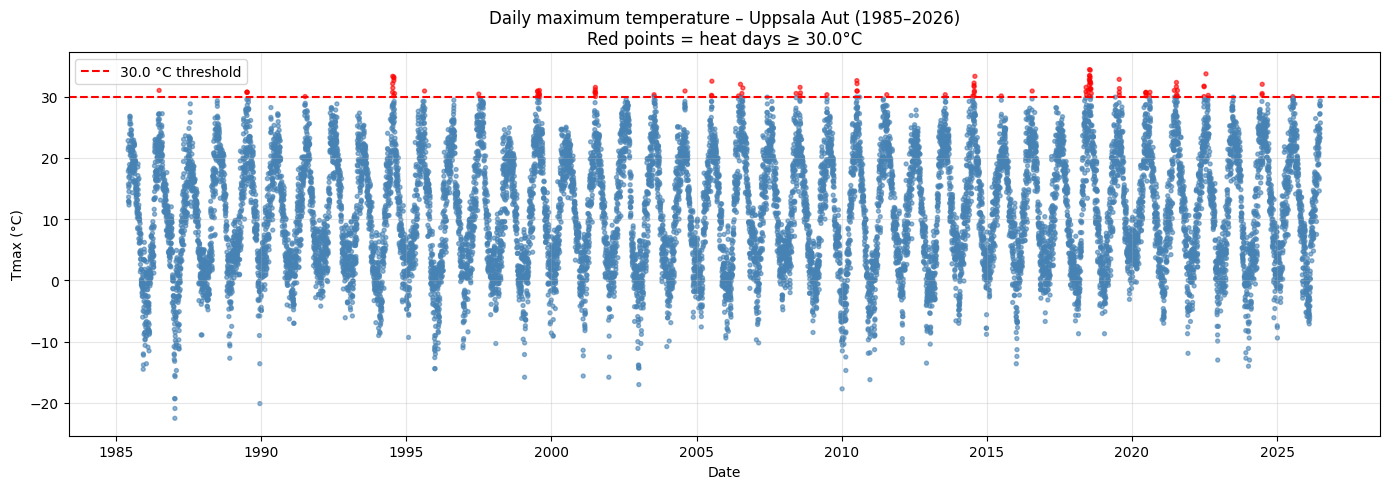

In [15]:
plt.figure(figsize=(14, 5))
plt.scatter(df["date"], df["tmax"], c=df["is_heat_day"].map({True: "red", False: "steelblue"}), s=8, alpha=0.6)
plt.axhline(THRESHOLD, color="red", linestyle="--", label=f"{THRESHOLD} °C threshold")
plt.title(f"Daily maximum temperature – Uppsala Aut (1985–2026)\nRed points = heat days ≥ {THRESHOLD}°C")
plt.ylabel("Tmax (°C)")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Progress so far – SMHI Data & Heatwave Analysis (Uppsala)

### What we have done

1. **Connected to SMHI Open Data API** (Meteorological Observations)
2. **Selected the best station for Uppsala**
   - Station ID: **97510 - Uppsala Aut** (active automatic station)
   - Rejected the old “Uppsala” station (inactive) and the airport station (less representative of the city)

3. **Downloaded daily maximum temperature (parameter 20)**
   - Period: **1 June 1985 - 30 June 2026** (~41 years)
   - Total days: **15,004**

4. **Cleaned the data**
   - Columns kept: `date`, `tmax`, `quality`

5. **Heatwave definitions aligned with Swedish practice**
   - **Level 1 (Notice / health-relevant)**: Tmax ≥ **27 °C** for ≥ **3 consecutive days**
   - **Level 2 (Warning / extreme)**: Tmax ≥ **30 °C** for ≥ **3 consecutive days**
   - (Optional later: classic SMHI definition ≥ 25 °C for ≥ 5 days)

### Why these thresholds?
- Pure ≥ 30 °C is too rare in Uppsala and misses most periods that already increase health risk.
- Swedish epidemiological studies show mortality rises clearly around 26-27 °C for a few consecutive days.
- SMHI issues a “Meddelande om höga temperaturer” at ≈ 26 °C / 3 days and yellow warnings at 30 °C / 3-4 days.
- This multi-level approach lets the future tool answer both everyday warm spells and rare extreme events.

### Next steps
- Run the Level 1 and Level 2 analysis side-by-side
- Calculate frequency per decade
- Build the first version of the deterministic risk function

In [16]:
def find_heatwaves(df, threshold, min_duration=3):
    """
    Find heatwave periods where Tmax >= threshold for at least min_duration consecutive days.
    Returns a DataFrame with start, end, duration, max_tmax, mean_tmax.
    """
    temp = df.copy()
    temp["is_hot"] = temp["tmax"] >= threshold

    # Group consecutive hot days
    temp["group"] = (temp["is_hot"] != temp["is_hot"].shift()).cumsum()
    temp.loc[~temp["is_hot"], "group"] = 0

    heatwaves = (
        temp[temp["is_hot"]]
        .groupby("group")
        .agg(
            start=("date", "min"),
            end=("date", "max"),
            duration=("date", "count"),
            max_tmax=("tmax", "max"),
            mean_tmax=("tmax", "mean")
        )
        .reset_index(drop=True)
    )

    # Keep only periods that meet the minimum duration
    heatwaves = heatwaves[heatwaves["duration"] >= min_duration].reset_index(drop=True)
    return heatwaves

In [17]:
# Level 1: ≥ 27 °C for ≥ 3 consecutive days (health-relevant / notice level)
hw_27 = find_heatwaves(df_hist_clean, threshold=27.0, min_duration=3)

# Level 2: ≥ 30 °C for ≥ 3 consecutive days (warning / extreme level)
hw_30 = find_heatwaves(df_hist_clean, threshold=30.0, min_duration=3)

print("=" * 60)
print("LEVEL 1 – Tmax ≥ 27 °C for ≥ 3 consecutive days")
print("=" * 60)
print(f"Number of heatwave periods: {len(hw_27)}")
print(hw_27.sort_values("start").to_string())
print("\nDuration statistics:")
print(hw_27["duration"].describe())

print("\n" + "=" * 60)
print("LEVEL 2 – Tmax ≥ 30 °C for ≥ 3 consecutive days")
print("=" * 60)
print(f"Number of heatwave periods: {len(hw_30)}")
print(hw_30.sort_values("start").to_string())
print("\nDuration statistics:")
print(hw_30["duration"].describe())

LEVEL 1 – Tmax ≥ 27 °C for ≥ 3 consecutive days
Number of heatwave periods: 65
        start        end  duration  max_tmax  mean_tmax
0  1986-06-25 1986-06-27         3      31.0  28.433333
1  1988-06-26 1988-06-28         3      29.3  28.866667
2  1989-07-07 1989-07-09         3      30.7  30.000000
3  1989-07-23 1989-07-27         5      29.6  28.500000
4  1991-07-04 1991-07-09         6      30.0  28.516667
5  1994-07-09 1994-07-15         7      33.3  30.242857
6  1994-07-25 1994-07-29         5      33.2  31.320000
7  1994-07-31 1994-08-02         3      29.2  28.400000
8  1995-07-29 1995-08-02         5      29.2  28.300000
9  1996-08-19 1996-08-22         4      29.4  28.425000
10 1997-07-21 1997-07-24         4      29.6  29.025000
11 1997-08-07 1997-08-09         3      28.6  28.000000
12 1997-08-19 1997-08-21         3      29.2  28.933333
13 1997-08-26 1997-08-29         4      28.9  28.175000
14 1999-07-09 1999-07-14         6      30.9  30.083333
15 1999-07-29 1999-08-04 

In [18]:
def add_decade(hw_df):
    hw = hw_df.copy()
    hw["decade"] = (hw["start"].dt.year // 10) * 10
    return hw.groupby("decade").size().rename("count")

print("Number of Level-1 heatwaves (≥27 °C, ≥3 days) per decade:")
print(add_decade(hw_27))

print("\nNumber of Level-2 heatwaves (≥30 °C, ≥3 days) per decade:")
print(add_decade(hw_30))

Number of Level-1 heatwaves (≥27 °C, ≥3 days) per decade:
decade
1980     4
1990    12
2000    16
2010    19
2020    14
Name: count, dtype: int64

Number of Level-2 heatwaves (≥30 °C, ≥3 days) per decade:
decade
1990    3
2000    1
2010    6
2020    3
Name: count, dtype: int64


In [19]:
# Level 3: Classic SMHI definition – Tmax ≥ 25 °C for ≥ 5 consecutive days
hw_25 = find_heatwaves(df_hist_clean, threshold=25.0, min_duration=5)

print("=" * 60)
print("LEVEL 3 – Tmax ≥ 25 °C for ≥ 5 consecutive days (SMHI classic)")
print("=" * 60)
print(f"Number of heatwave periods: {len(hw_25)}")
print("\nDuration statistics:")
print(hw_25["duration"].describe())
print("\nNumber per decade:")
print(add_decade(hw_25))
print("\nLongest / hottest events:")
print(hw_25.sort_values("duration", ascending=False).head(8))

LEVEL 3 – Tmax ≥ 25 °C for ≥ 5 consecutive days (SMHI classic)
Number of heatwave periods: 65

Duration statistics:
count    65.000000
mean      8.015385
std       4.389235
min       5.000000
25%       5.000000
50%       7.000000
75%       9.000000
max      29.000000
Name: duration, dtype: float64

Number per decade:
decade
1980     4
1990    17
2000    17
2010    12
2020    15
Name: count, dtype: int64

Longest / hottest events:
        start        end  duration  max_tmax  mean_tmax
48 2018-07-08 2018-08-05        29      34.4  30.075862
44 2014-07-17 2014-08-06        21      33.3  28.600000
25 2002-08-07 2002-08-27        21      29.0  27.476190
9  1994-07-20 1994-08-06        18      33.2  28.577778
63 2025-07-16 2025-07-28        13      30.0  28.746154
59 2023-06-20 2023-07-01        12      29.9  27.333333
57 2022-08-09 2022-08-20        12      30.2  27.683333
54 2021-07-08 2021-07-18        11      32.3  28.563636


In [20]:
def compute_heatwave_risk(days: int, temp: float, df_hist=df_hist_clean):
    """
    Deterministic heatwave risk estimator for Uppsala (station 97510).

    Parameters
    ----------
    days : int
        Number of consecutive days expected
    temp : float
        Expected daily maximum temperature (°C)

    Returns
    -------
    dict with:
        - level: "none" / "level1" / "level2" / "level3"
        - description: short text
        - historical_count: how many similar events occurred 1985–2026
        - risk_score: simple empirical score (0–1)
        - comment: extra context
    """

    # Determine which level the query matches
    if temp >= 30 and days >= 3:
        level = "level2"
        description = f"Extreme heat (Level 2): ≥30°C for ≥3 days"
        # Count historical Level 2 events
        hist = find_heatwaves(df_hist, threshold=30.0, min_duration=3)
        historical_count = len(hist)
        # Simple risk score: rarer = higher relative risk
        risk_score = min(1.0, 0.4 + (historical_count / 20))
        comment = "This matches SMHI yellow-warning territory. Rare but high-impact in Uppsala."

    elif temp >= 27 and days >= 3:
        level = "level1"
        description = f"Health-relevant heat (Level 1): ≥27°C for ≥3 days"
        hist = find_heatwaves(df_hist, threshold=27.0, min_duration=3)
        historical_count = len(hist)
        risk_score = min(1.0, 0.25 + (historical_count / 80))
        comment = "Temperature range where Swedish studies show clear increases in mortality risk."

    elif temp >= 25 and days >= 5:
        level = "level3"
        description = f"Classic SMHI heatwave (Level 3): ≥25°C for ≥5 days"
        hist = find_heatwaves(df_hist, threshold=25.0, min_duration=5)
        historical_count = len(hist)
        risk_score = min(1.0, 0.15 + (historical_count / 120))
        comment = "Official SMHI climatological definition of a heatwave."

    else:
        level = "none"
        description = "Below defined heatwave thresholds"
        historical_count = 0
        risk_score = 0.05
        comment = "Does not meet Level 1, 2 or 3 criteria used in this tool."

    return {
        "level": level,
        "description": description,
        "historical_count": historical_count,
        "risk_score": round(risk_score, 2),
        "comment": comment,
        "query": f"{days} days at {temp}°C"
    }

In [21]:
# Test a few realistic queries
examples = [
    (3, 28),   # typical Level 1
    (4, 31),   # Level 2
    (6, 26),   # Level 3
    (2, 29),   # too short
    (5, 24),   # too cool
    (8, 32),   # strong Level 2 (like 2018)
]

print("Testing the risk function:\n")
for days, temp in examples:
    result = compute_heatwave_risk(days, temp)
    print(f"Query: {days} days at {temp}°C")
    print(f"  → Level: {result['level']}")
    print(f"  → {result['description']}")
    print(f"  → Historical similar events: {result['historical_count']}")
    print(f"  → Risk score: {result['risk_score']}")
    print(f"  → {result['comment']}")
    print("-" * 50)

Testing the risk function:

Query: 3 days at 28°C
  → Level: level1
  → Health-relevant heat (Level 1): ≥27°C for ≥3 days
  → Historical similar events: 65
  → Risk score: 1.0
  → Temperature range where Swedish studies show clear increases in mortality risk.
--------------------------------------------------
Query: 4 days at 31°C
  → Level: level2
  → Extreme heat (Level 2): ≥30°C for ≥3 days
  → Historical similar events: 13
  → Risk score: 1.0
  → This matches SMHI yellow-warning territory. Rare but high-impact in Uppsala.
--------------------------------------------------
Query: 6 days at 26°C
  → Level: level3
  → Classic SMHI heatwave (Level 3): ≥25°C for ≥5 days
  → Historical similar events: 65
  → Risk score: 0.69
  → Official SMHI climatological definition of a heatwave.
--------------------------------------------------
Query: 2 days at 29°C
  → Level: none
  → Below defined heatwave thresholds
  → Historical similar events: 0
  → Risk score: 0.05
  → Does not meet Level 1, 

## Summary of this notebook

### Goal
Acquire and explore long-term daily maximum temperature data for Uppsala and define heatwave levels that are meaningful for local health risk.

### Data
- **Source**: SMHI Open Data (Meteorological Observations)
- **Station**: 97510 - Uppsala Aut (active automatic station)
- **Parameter**: Daily maximum temperature (ID 20)
- **Period**: 1 June 1985 - 30 June 2026 (15 004 days)

### Heatwave definitions used (aligned with Swedish practice)

| Level | Threshold              | Min. duration | Meaning |
|-------|------------------------|---------------|---------|
| **1** | ≥ 27 °C                | ≥ 3 days      | Health-relevant / notice level (mortality risk starts rising) |
| **2** | ≥ 30 °C                | ≥ 3 days      | Extreme / SMHI yellow-warning level |
| **3** | ≥ 25 °C                | ≥ 5 days      | Classic SMHI climatological heatwave |

### Main findings
- Level 1 events are relatively common and have increased over time.
- Level 2 events are rare (only 13 in 41 years) but high-impact (especially 2018).
- Level 3 captures longer warm periods, including the very long 2018 event (29 days).

### Deliverable
A first working version of the deterministic function `compute_heatwave_risk(days, temp)` that will be improved and used by the LLM agent in later notebooks.

In [22]:
# Save key objects so we can load them quickly in the next notebook
df_hist_clean.to_csv("uppsala_tmax_1985_2026.csv", index=False)

hw_27.to_csv("heatwaves_level1_27C.csv", index=False)
hw_30.to_csv("heatwaves_level2_30C.csv", index=False)
hw_25.to_csv("heatwaves_level3_25C.csv", index=False)

print("Files saved:")
print("  - uppsala_tmax_1985_2026.csv")
print("  - heatwaves_level1_27C.csv")
print("  - heatwaves_level2_30C.csv")
print("  - heatwaves_level3_25C.csv")

Files saved:
  - uppsala_tmax_1985_2026.csv
  - heatwaves_level1_27C.csv
  - heatwaves_level2_30C.csv
  - heatwaves_level3_25C.csv
